# Fig 2 — ATAC-seq accessibility: bulk differential accessibility (GM12878 vs IMR90)

Comprehensive, end-to-end notebook for the **bulk ATAC-seq ground truth** used in the
Fig 2 single-cell NOMe-HiC accessibility comparison. Everything lives here: **data
download → DiffBind → DESeq2 → result analysis → plotting**.

**Biology / design.** Differential chromatin accessibility between **GM12878** (3 reps)
and **IMR90** (2 reps). ENCODE, same lab/pipeline (Michael Snyder, Stanford), GRCh38.
Consensus peaks built from each line's IDR-thresholded peak set; reads counted from the
replicate alignment BAMs (duplicate removal, mapQ≥30, GRCh38 blacklist, summits=250);
tested with **DiffBind → DESeq2**.

**Environment.** Run with the **R (scnomehic_diff)** kernel — conda env `scnomehic_diff`
(clone of `scnomehic` + `bioconductor-{methylkit,diffbind,deseq2,csaw,edger}`; built by
`codes/create_diff_env.sh`). DiffBind, DESeq2, edgeR, Rsamtools all load there.

**Resume behaviour.** The two heavy steps — BAM indexing and `dba.count` — are guarded:
if `diffbind_counts.rds` already exists (e.g. produced by `codes/diffbind_atac.sh` on
SLURM, recommended for the full ~30 GB count) it is loaded instead of recomputed. So this
notebook works both as the *driver* of the analysis and as an *interactive re-analysis* of
a precomputed run.

> *Scope:* Parts 0–4 build the **bulk** reference. **Part 5** adds the **single-cell
> NOMe-HiC GpC (GCH) accessibility** over the differential peaks and compares it to the bulk.

In [2]:
suppressPackageStartupMessages({
  library(DiffBind); library(GenomicRanges); library(Rsamtools)
  library(ggplot2);  library(patchwork);    library(scales); library(data.table)
})
set.seed(42)

# per-peak (column) z-score, NaN-safe; used by the sc-accessibility heatmaps (Parts 5-6)
zscore_cols <- function(M) {
  mu <- colMeans(M, na.rm = TRUE); s <- apply(M, 2, sd, na.rm = TRUE)
  s[is.na(s) | s == 0] <- 1
  sweep(sweep(M, 2, mu, "-"), 2, s, "/")
}

FIG2   <- "/gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/fig2"
DATA   <- file.path(FIG2, "data/bulk")
OUT    <- file.path(FIG2, "analysis/diff_accessibility")
OUTFIG <- file.path(OUT, "figures")
dir.create(OUTFIG, showWarnings = FALSE, recursive = TRUE)
B <- function(...) file.path(FIG2, ...)

# sample design
SAMPLES   <- c("GM12878_r1","GM12878_r2","GM12878_r3","IMR90_r1","IMR90_r2")
GROUP     <- setNames(c("GM12878","GM12878","GM12878","IMR90","IMR90"), SAMPLES)
GROUP_COL <- c(GM12878 = "#2166AC", IMR90 = "#B2182B")

# tunables
FDR_TH  <- 0.05   # DiffBind significance
FOLD_TH <- 1      # |log2FC| highlight on volcano
NCORE   <- 4      # cores for dba.count

cat("DiffBind", as.character(packageVersion("DiffBind")),
    "| DESeq2", as.character(packageVersion("DESeq2")), "\n")


ERROR: Error in library(DiffBind): there is no package called ‘DiffBind’


## 1. Data — ENCODE ATAC-seq replicates

Both experiments are ENCODE, GRCh38, Snyder lab (Stanford), so the alignment/peak
pipelines match — appropriate for a cross-cell-line differential test.

| Cell line | Experiment | Role | Accession | File |
|-----------|-----------|------|-----------|------|
| GM12878 | ENCSR637XSC | rep1 BAM | ENCFF981FXV | `GM12878/atac/bam/ENCFF981FXV.bam` |
| GM12878 | ENCSR637XSC | rep2 BAM | ENCFF962FMH | `GM12878/atac/bam/ENCFF962FMH.bam` |
| GM12878 | ENCSR637XSC | rep3 BAM | ENCFF440GRZ | `GM12878/atac/bam/ENCFF440GRZ.bam` |
| GM12878 | ENCSR637XSC | IDR peaks | ENCFF871TST | `GM12878/atac/peaks/ENCFF871TST.bed.gz` |
| IMR90 | ENCSR200OML | rep1 BAM | ENCFF848XMR | `IMR90/atac/bam/ENCFF848XMR.bam` |
| IMR90 | ENCSR200OML | rep2 BAM | ENCFF715NAV | `IMR90/atac/bam/ENCFF715NAV.bam` |
| IMR90 | ENCSR200OML | IDR peaks | ENCFF114GDS | `IMR90/atac/peaks/ENCFF114GDS.bed.gz` |

Downloaded by **`codes/download_atac_bams.sh`** (`wget -c` from
`https://www.encodeproject.org/files/<ACC>/@@download/<ACC>.<ext>`, ~32 GB total).
The cell below verifies the files rather than re-downloading.

In [ ]:
# paths (match codes/diffbind_atac.R)
bam <- list(
  GM12878_r1 = B("data/bulk/GM12878/atac/bam/ENCFF981FXV.bam"),
  GM12878_r2 = B("data/bulk/GM12878/atac/bam/ENCFF962FMH.bam"),
  GM12878_r3 = B("data/bulk/GM12878/atac/bam/ENCFF440GRZ.bam"),
  IMR90_r1   = B("data/bulk/IMR90/atac/bam/ENCFF848XMR.bam"),
  IMR90_r2   = B("data/bulk/IMR90/atac/bam/ENCFF715NAV.bam"))
peak <- list(
  GM12878 = B("data/bulk/GM12878/atac/peaks/ENCFF871TST.bed.gz"),
  IMR90   = B("data/bulk/IMR90/atac/peaks/ENCFF114GDS.bed.gz"))

inv <- data.frame(
  sample = names(bam), bam = unlist(bam),
  exists = file.exists(unlist(bam)),
  size_GB = round(file.info(unlist(bam))$size / 1e9, 2), row.names = NULL)
print(inv)
stopifnot(all(inv$exists), all(file.exists(unlist(peak))))
cat("\nAll BAMs + peak sets present. If any were missing, run:",
    "\n  bash codes/download_atac_bams.sh\n")


### 1b. Index BAMs (resume-guarded)
DiffBind's `summarizeOverlaps` needs coordinate-sorted, indexed BAMs. Index from R with `Rsamtools::indexBam` only where the `.bai` is missing.

In [ ]:
for (s in names(bam)) {
  bai <- paste0(bam[[s]], ".bai")
  if (file.exists(bai)) { cat("index exists:", s, "\n") }
  else { cat("indexing", s, "...\n"); Rsamtools::indexBam(bam[[s]]) }
}
cat("BAM indexing done.\n")


## 2. Run DiffBind → DESeq2

Build the sample sheet, form the consensus peak set, count reads per peak across the 5
replicates, then normalize / contrast / analyze with DESeq2.

**Peak set (union of per-cell-line IDR peaks).** Each cell line's ENCODE **IDR-thresholded**
peak set is assigned to all of that line's replicates (GM→ENCFF871TST ×3, IMR→ENCFF114GDS ×2).
With `dba.count(minOverlap = 2)` a merged region is kept if it appears in ≥2 peaksets — so GM
peaks (in 3 entries) and IMR peaks (in 2 entries) both pass, and the consensus becomes the
**merged UNION of the two cell lines' IDR peaks**. This is what we want for a 2-condition test:
it retains cell-line-specific peaks. (An *intersection* would discard exactly the peaks that
are most likely to be differential — do not use it.)

**Read filtering.** The ENCODE `alignments` BAMs are already deduplicated, chrM-removed,
proper-pairs-only, and secondary-removed, but **not mapQ-thresholded** (~12% of reads are
mapQ<30 multimappers). Because `bUseSummarizeOverlaps=TRUE` makes DiffBind **ignore** `mapQCth`,
the mapQ≥30 filter is applied via `DBA$config$scanbamparam` (a `ScanBamParam`), per the DiffBind
manual. No extra dedup/chrM step is needed — ENCODE already did those.

> **Heavy step:** `dba.count` reads all 5 BAMs (~30 GB). On a login node prefer the SLURM
> job `sbatch codes/diffbind_atac.sh` (64 GB, 8 cpu); this notebook then just loads the
> resulting `diffbind_counts.rds`. The guard below recomputes only if that file is absent.

In [ ]:
samples <- data.frame(
  SampleID  = SAMPLES,
  Condition = unname(GROUP[SAMPLES]),
  Replicate = c(1,2,3,1,2),
  bamReads  = unlist(bam[SAMPLES]),
  Peaks     = c(rep(peak$GM12878, 3), rep(peak$IMR90, 2)),
  PeakCaller = "narrow", stringsAsFactors = FALSE)
write.table(samples, file.path(OUT, "diffbind_samplesheet.tsv"),
            sep = "\t", quote = FALSE, row.names = FALSE)
samples[, c("SampleID","Condition","Replicate")]


In [ ]:
counts_rds <- file.path(OUT, "diffbind_counts.rds")
if (file.exists(counts_rds)) {
  message("Loading precomputed counts: ", counts_rds)
  dbo <- readRDS(counts_rds)
} else {
  message("dba() build ...")
  dbo <- dba(sampleSheet = samples)
  message("dba.blacklist (GRCh38) ...")
  dbo <- tryCatch(dba.blacklist(dbo, blacklist = DBA_BLACKLIST_GRCH38, greylist = FALSE),
                  error = function(e) { message("  blacklist skipped: ", conditionMessage(e)); dbo })

  # ATAC mapQ>=30 filter. ENCODE 'alignments' BAMs are already dedup/chrM/secondary
  # filtered but NOT mapQ-thresholded. With bUseSummarizeOverlaps=TRUE, mapQCth is
  # IGNORED -> pass the filter through ScanBamParam (DiffBind manual, dba.count).
  dbo$config$scanbamparam <- Rsamtools::ScanBamParam(mapqFilter = 30)

  message("dba.count (summits=250, minOverlap=2 -> union, mapQ>=30 via ScanBamParam) -- heavy ...")
  dbo <- dba.count(dbo, summits = 250, minOverlap = 2,
                   bUseSummarizeOverlaps = TRUE, bParallel = TRUE)
  saveRDS(dbo, counts_rds)
}
dbo


In [ ]:
# normalize (DESeq2 default), contrast by condition, analyze
dbo <- dba.normalize(dbo)
dbo <- dba.contrast(dbo, categories = DBA_CONDITION, minMembers = 2)
dbo <- dba.analyze(dbo, method = DBA_DESEQ2)
dba.show(dbo, bContrasts = TRUE)


## 3. Result analysis — report + significance + export

In [ ]:
# full report (th=1 -> all consensus peaks); bCounts keeps per-sample counts
rep_all <- dba.report(dbo, method = DBA_DESEQ2, th = 1, bCounts = TRUE)
df <- as.data.frame(rep_all)
cat("consensus peaks:", nrow(df), "\ncolumns:\n"); print(names(df))

n_sig <- sum(!is.na(df$FDR) & df$FDR < FDR_TH)
sig   <- df[!is.na(df$FDR) & df$FDR < FDR_TH, ]
cat(sprintf("\nsignificant (FDR<%.2g): %d / %d (%.1f%%) | up Fold>0: %d | down Fold<0: %d\n",
            FDR_TH, n_sig, nrow(df), 100*n_sig/nrow(df), sum(sig$Fold>0), sum(sig$Fold<0)))

# export: all peaks (with per-sample counts) + significant BED
write.table(df, gzfile(file.path(OUT, "da_peaks_all.txt.gz")),
            sep = "\t", quote = FALSE, row.names = FALSE)
sig$dir <- ifelse(sig$Fold > 0, "up_in_first", "down_in_first")
bed <- data.frame(chrom = sig$seqnames, start = sig$start - 1L, end = sig$end,
                  name = sig$dir, score = round(sig$Fold, 3), strand = ".", FDR = sig$FDR)
write.table(bed, file.path(OUT, "da_peaks_sig.bed"),
            sep = "\t", quote = FALSE, row.names = FALSE, col.names = FALSE)
cat("wrote da_peaks_all.txt.gz + da_peaks_sig.bed to", OUT, "\n")
head(df[order(df$FDR), c("seqnames","start","end","Conc","Fold","p.value","FDR")], 10)


## 4. Plotting
### 4a. DiffBind-native diagnostics (PCA, MA, volcano, correlation heatmap)

In [ ]:
pdf(file.path(OUTFIG, "fig2_atac_diffbind_native.pdf"), width = 7, height = 6)
tryCatch(dba.plotPCA(dbo, DBA_CONDITION, label = DBA_ID), error = function(e) NULL)
tryCatch(dba.plotMA(dbo, method = DBA_DESEQ2),            error = function(e) NULL)
tryCatch(dba.plotVolcano(dbo),                            error = function(e) NULL)
tryCatch(dba.plotHeatmap(dbo, correlations = TRUE),       error = function(e) NULL)
dev.off()

options(repr.plot.width = 7, repr.plot.height = 6)
dba.plotPCA(dbo, DBA_CONDITION, label = DBA_ID)


### 4b. ggplot QC — PCA + sample correlation (from per-sample counts)

In [ ]:
count_cols <- intersect(SAMPLES, names(df))
M <- as.matrix(df[, count_cols, drop = FALSE]); mode(M) <- "numeric"
logM <- log2(M + 1)

v <- apply(logM, 1, var)
topv <- order(v, decreasing = TRUE)[seq_len(min(20000L, nrow(logM)))]
pc <- prcomp(t(logM[topv, , drop = FALSE]), scale. = FALSE)
ve <- 100 * pc$sdev^2 / sum(pc$sdev^2)
pca_df <- data.frame(sample = rownames(pc$x), PC1 = pc$x[,1], PC2 = pc$x[,2],
                     group = GROUP[rownames(pc$x)])
p_pca <- ggplot(pca_df, aes(PC1, PC2, colour = group, label = sample)) +
  geom_point(size = 3) + ggrepel::geom_text_repel(size = 3, show.legend = FALSE) +
  scale_colour_manual(values = GROUP_COL) +
  labs(title = "ATAC replicate PCA", x = sprintf("PC1 (%.1f%%)", ve[1]),
       y = sprintf("PC2 (%.1f%%)", ve[2])) + theme_bw()

cc <- cor(logM, method = "pearson")
cc_long <- data.frame(
  s1 = factor(rep(colnames(cc), each = ncol(cc)), levels = SAMPLES),
  s2 = factor(rep(rownames(cc), times = ncol(cc)), levels = rev(SAMPLES)),
  r  = as.numeric(cc))
p_cor <- ggplot(cc_long, aes(s1, s2, fill = r)) + geom_tile() +
  geom_text(aes(label = sprintf("%.2f", r)), size = 3) +
  scale_fill_gradient(low = "white", high = "#2166AC", limits = c(min(cc), 1), name = "Pearson r") +
  labs(title = "Sample correlation (log2 counts)", x = NULL, y = NULL) +
  theme_bw() + theme(axis.text.x = element_text(angle = 45, hjust = 1), panel.grid = element_blank())

qc <- p_pca | p_cor
ggsave(file.path(OUTFIG, "fig2_atac_diffbind_qc.pdf"), qc, width = 11, height = 5)
options(repr.plot.width = 11, repr.plot.height = 5); qc


### 4c. ggplot — MA + volcano

In [ ]:
df$sig <- !is.na(df$FDR) & df$FDR < FDR_TH
df$dir <- ifelse(!df$sig, "ns", ifelse(df$Fold > 0, "up", "down"))
dir_col <- c(ns = "grey75", up = "#B2182B", down = "#2166AC")

p_ma <- ggplot(df, aes(Conc, Fold, colour = dir)) +
  geom_point(size = .5, alpha = .4) + scale_colour_manual(values = dir_col, name = NULL) +
  geom_hline(yintercept = 0, linetype = 2, colour = "grey40") +
  labs(title = "MA — ATAC differential accessibility",
       x = "Concentration (mean log2 reads)", y = "Fold (log2 FC)") +
  theme_bw() + guides(colour = guide_legend(override.aes = list(size = 2, alpha = 1)))

p_vol <- ggplot(df, aes(Fold, -log10(FDR), colour = dir)) +
  geom_point(size = .5, alpha = .4) + scale_colour_manual(values = dir_col, name = NULL) +
  geom_vline(xintercept = c(-FOLD_TH, FOLD_TH), linetype = 2, colour = "grey40") +
  geom_hline(yintercept = -log10(FDR_TH), linetype = 2, colour = "grey40") +
  labs(title = "Volcano — ATAC differential accessibility",
       x = "Fold (log2 FC)", y = expression(-log[10]~FDR)) +
  theme_bw() + guides(colour = guide_legend(override.aes = list(size = 2, alpha = 1)))

dap <- p_ma | p_vol
ggsave(file.path(OUTFIG, "fig2_atac_diffbind_ma_volcano.pdf"), dap, width = 11, height = 5)
options(repr.plot.width = 11, repr.plot.height = 5); dap


## 5. Single-cell GpC (GCH) accessibility over the differential peaks

For each utilized cell, accessibility in a differential peak = **methylated GCH reads ÷ total
GCH reads** summed over the peak (the NOMe-HiC GpC openness readout), computed from each cell's
`...GCH.6plus2.bed.gz` — identical to the pipeline's per-bin `methylation_level`.

The **cell × peak** matrix is heavy to build (441 QC-passed cells × large GCH beds), so it is
produced by **`codes/build_sc_gch_peak_matrix.sh`** (SLURM) over the **top-1000 differential
peaks** (by FDR, split up/down; 1000 so plenty remain after dropping no-coverage peaks).
This notebook just loads and visualises it.

Outputs consumed (in `analysis/diff_accessibility/sc_gch/`): `peaks_top1000.tsv`,
`sc_gch_accessibility_top1000.tsv.gz` (0..1, NaN = no reads), `sc_gch_total_top1000.tsv.gz`.

> Run order: DiffBind (Parts 2–3 / `da_peaks_all.txt.gz`) → `sbatch codes/build_sc_gch_peak_matrix.sh` → this part.

In [ ]:
SC_GCH <- file.path(OUT, "sc_gch")
N_TOP  <- 1000
acc_f  <- file.path(SC_GCH, sprintf("sc_gch_accessibility_top%d.tsv.gz", N_TOP))
tot_f  <- file.path(SC_GCH, sprintf("sc_gch_total_top%d.tsv.gz", N_TOP))
pk_f   <- file.path(SC_GCH, sprintf("peaks_top%d.tsv", N_TOP))
if (!file.exists(acc_f))
  stop("Missing ", acc_f, "\n  -> run: sbatch codes/build_sc_gch_peak_matrix.sh  (needs da_peaks_all.txt.gz)")

acc <- as.data.frame(fread(acc_f), check.names = FALSE); rownames(acc) <- acc$cell; acc$cell <- NULL
tot <- as.data.frame(fread(tot_f), check.names = FALSE); rownames(tot) <- tot$cell; tot$cell <- NULL
acc <- as.matrix(acc); tot <- as.matrix(tot)               # cells x peaks
pk  <- as.data.frame(fread(pk_f))                          # peak_id, Fold, FDR, dir, ...
cat("sc GCH accessibility matrix:", nrow(acc), "cells x", ncol(acc), "peaks\n")
cat("peaks:", sum(pk$dir=="up"), "up /", sum(pk$dir=="down"), "down | ",
    "mean per-cell peaks with reads:", round(mean(rowSums(tot>0)),1), "\n")
acc[1:5, 1:4]


### 5a. Sparsity / coverage by cell type

Single-cell GpC accessibility is sparse: many (cell, peak) pairs have **no GCH reads** (NaN).
Here we quantify that per cell type. Key number = **peaks covered in ≥20% of cells** in each
type — those are the peaks usable in the heatmap. If that count is small (rule of thumb
< ~150 per type), rebuild with more peaks (raise `N_TOP` in `build_sc_gch_peak_matrix.sh`).

In [ ]:
SCROOT <- "/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline"
# Cell-type labels from metadata.txt.gz (501 clustered cells) -> labels ~413 of the 441 matrix
# cells (the fuller source; metadata_with_cell_type.txt.gz only has 288). The `cluster` column
# IS the cell type: cluster 1 = GM12878, cluster 2 = IMR90 (validated 286/288 concordant with
# the annotated file). Matrix ids use an underscore vs metadata's dot -> normalise the FIRST dot.
meta <- as.data.frame(fread(file.path(SCROOT, "metadata.txt.gz")))   # cluster,cluster_color,sample,name
ct   <- setNames(c("1"="GM12878","2"="IMR90")[as.character(meta$cluster)],
                 sub(".", "_", meta$name, fixed = TRUE))
lab  <- intersect(rownames(acc), names(ct))
ctL  <- ct[lab]
covered <- (tot[lab, , drop = FALSE] > 0)            # logical: cells x peaks with >=1 GCH read

report <- function(mask, label) {
  C <- covered[mask, , drop = FALSE]
  pc <- rowSums(C)                                   # peaks-with-reads per cell
  cat(sprintf("%-8s n=%3d | entries covered=%5.1f%% | peaks/cell median=%4d (IQR %d-%d) | peaks in >=20%% cells=%d/%d | peaks in >=50%% cells=%d\n",
      label, sum(mask), 100*mean(C),
      as.integer(median(pc)), as.integer(quantile(pc,.25)), as.integer(quantile(pc,.75)),
      sum(colMeans(C) >= 0.2), ncol(C), sum(colMeans(C) >= 0.5)))
}
cat("labelled cells:", length(lab), "of", nrow(acc), "\n"); print(table(ctL))
gm <- ctL=="GM12878"; im <- ctL=="IMR90"
report(rep(TRUE,length(ctL)), "ALL"); if(any(gm)) report(gm,"GM12878"); if(any(im)) report(im,"IMR90")

# peaks usable in BOTH types (>=20% cells each) -> what the heatmap can actually show
usable <- (colMeans(covered[gm,,drop=FALSE])>=0.2) & (colMeans(covered[im,,drop=FALSE])>=0.2)
cat(sprintf("\npeaks covered in >=20%% of cells in BOTH types: %d / %d\n", sum(usable), ncol(covered)))
if (sum(usable) < 150)
  cat("  -> SPARSE: consider rebuilding with larger N_TOP in build_sc_gch_peak_matrix.sh\n")

# visualise: per-cell coverage distribution + per-peak coverage by cell type
d1 <- data.frame(peaks_with_reads = rowSums(covered), cell_type = ctL)
pcell <- ggplot(d1, aes(peaks_with_reads, fill = cell_type)) +
  geom_histogram(bins = 40, alpha = .7, position = "identity") +
  scale_fill_manual(values = GROUP_COL) +
  labs(title = "Peaks with GCH reads per cell", x = "peaks with >=1 read", y = "cells") + theme_bw()
d2 <- data.frame(frac_cells = c(colMeans(covered[gm,,drop=FALSE]), colMeans(covered[im,,drop=FALSE])),
                 cell_type = rep(c("GM12878","IMR90"), each = ncol(covered)))
ppeak <- ggplot(d2, aes(frac_cells, fill = cell_type)) +
  geom_histogram(bins = 40, alpha = .7, position = "identity") +
  geom_vline(xintercept = 0.2, linetype = 2) +
  scale_fill_manual(values = GROUP_COL) +
  labs(title = "Fraction of cells covering each peak", x = "fraction of cells with reads", y = "peaks") + theme_bw()
sp <- pcell | ppeak
ggsave(file.path(OUTFIG, "fig2_atac_sc_gch_sparsity.pdf"), sp, width = 11, height = 4.5)
options(repr.plot.width = 11, repr.plot.height = 4.5); sp


### 5b. Cell-type labels + accessibility heatmap (cells × differential peaks)

In [ ]:
# labels (ct, lab, ctL) come from Part 5a; re-run 5a first if missing
stopifnot(exists("lab"), exists("ct"))
cat("labelled cells in matrix:", length(lab), "of", nrow(acc), "\n")
print(table(ct[lab]))

# zscore_cols() (per-peak, NaN-safe) is defined in the Part 0 setup cell. GCH accessibility is
# compressed (~0.8, ~1% diffs) so raw 0-1 colour shows no contrast; per-peak z makes GM/IMR visible.
A   <- acc[lab, pk$peak_id, drop = FALSE]
Az  <- zscore_cols(A)
cct <- ct[lab]
ord <- order(factor(cct, levels = c("GM12878","IMR90")), rowMeans(Az, na.rm = TRUE))
cell_order <- lab[ord]

sc_long <- data.frame(
  cell = factor(rep(cell_order, times = ncol(A)), levels = rev(cell_order)),
  peak = factor(rep(pk$peak_id, each = length(cell_order)), levels = pk$peak_id),
  beta = as.numeric(Az[cell_order, pk$peak_id]),
  cell_type = factor(rep(cct[cell_order], times = ncol(A)), levels = c("GM12878","IMR90")))
bulk_long <- data.frame(
  ref = factor("bulk ATAC Fold", levels = "bulk ATAC Fold"),
  peak = factor(pk$peak_id, levels = pk$peak_id), fold = pk$Fold)

# z-score colour scale (per-peak), reused by the imputed heatmap (6a)
fill_acc <- scale_fill_gradient2(low = "#2166AC", mid = "white", high = "#B2182B",
              midpoint = 0, limits = c(-2, 2), na.value = "grey90",
              name = "GCH z", oob = scales::squish)
tile_theme <- theme(axis.text.x = element_blank(), axis.ticks.x = element_blank(),
  axis.text.y = element_blank(), axis.ticks.y = element_blank(), panel.grid = element_blank(),
  panel.background = element_blank(),
  panel.border = element_rect(colour="black", fill=NA, linewidth=0.4),
  strip.background = element_blank(), legend.position = "right")

p_sc <- ggplot(sc_long, aes(peak, cell, fill = beta)) + geom_tile() + fill_acc +
  facet_grid(cell_type ~ ., scales = "free_y", space = "free_y", switch = "y") +
  labs(title = "Single cells (NOMe-HiC GCH, per-peak z-score)", x = NULL, y = NULL) + tile_theme +
  theme(strip.text.y.left = element_text(angle = 0, face = "bold"), strip.placement = "outside")
p_bk <- ggplot(bulk_long, aes(peak, ref, fill = fold)) + geom_tile() +
  scale_fill_gradient2(low="#2166AC", mid="white", high="#B2182B", midpoint=0,
                       name="log2FC", oob=scales::squish) +
  labs(x = "top-1000 differential peaks (up -> down in first group)", y = NULL) +
  tile_theme + theme(axis.text.y = element_text(face = "bold"))
comb <- (p_sc / p_bk) + plot_layout(heights = c(10, 1.0))
ggsave(file.path(OUTFIG, "fig2_atac_sc_gch_heatmap.pdf"), comb, width = 12, height = 9)
options(repr.plot.width = 12, repr.plot.height = 9); comb


### 5c. Concordance — single-cell GCH (GM−IMR) vs bulk ATAC Fold

In [ ]:
# bulk DiffBind Fold>0 == more accessible in IMR90 (verified: Conc_IMR90 > Conc_GM12878),
# so the concordant single-cell contrast is IMR90 - GM12878 -> expect POSITIVE r.
gm  <- colMeans(acc[lab[cct=="GM12878"], pk$peak_id, drop=FALSE], na.rm = TRUE)
imr <- colMeans(acc[lab[cct=="IMR90"],   pk$peak_id, drop=FALSE], na.rm = TRUE)
cc  <- data.frame(peak = pk$peak_id, fold = pk$Fold, dir = pk$dir,
                  sc_diff = imr - gm)   # >0 = more GCH-accessible in IMR90 cells
r <- cor(cc$fold, cc$sc_diff, use = "complete.obs")
cat(sprintf("Pearson r (bulk ATAC Fold vs sc GCH IMR-GM): %.3f  (expect >0 if concordant)\n", r))

p_con <- ggplot(cc, aes(fold, sc_diff, colour = dir)) +
  geom_hline(yintercept = 0, linetype = 2, colour = "grey60") +
  geom_vline(xintercept = 0, linetype = 2, colour = "grey60") +
  geom_point(alpha = .6, size = 1.3) +
  scale_colour_manual(values = c(up="#B2182B", down="#2166AC"), name = NULL) +
  labs(title = sprintf("sc GCH vs bulk ATAC concordance (r = %.2f)", r),
       x = "bulk ATAC Fold (log2FC, IMR90 vs GM12878)", y = "sc GCH accessibility (IMR90 - GM12878)") +
  theme_bw()
ggsave(file.path(OUTFIG, "fig2_atac_sc_gch_concordance.pdf"), p_con, width = 6, height = 5)
options(repr.plot.width = 6, repr.plot.height = 5); p_con


## 6. Imputation — Random Walk with Restart (scHiCluster-style)

The raw matrix is sparse (~23% of entries have reads). We (1) **subset to peaks covered in
≥20% of cells in EACH cell type**, then (2) **impute by Random Walk with Restart**, borrowing
scHiCluster's RWR operator.

**Adaptation.** scHiCluster runs RWR on each cell's 2-D contact map (a graph over genomic
loci). A peak-accessibility vector has no per-cell 2-D structure, so we instead build a
**cell–cell similarity graph** and apply the *same* RWR operator to diffuse each peak's signal
across similar cells (MAGIC-like smoothing with scHiCluster's restart kernel):

  P = row-normalized kNN affinity (transition matrix)
  S = rp · (I − (1−rp)·P)⁻¹      ← RWR operator, row-stochastic (rp = restart prob, scHiCluster uses 0.5)
  X_imputed = S · X₀             ← each cell = RWR-weighted average over the graph

Graph is built on **all cells** (richer neighborhood); plotting/concordance use the labelled
subset. Output: `analysis/diff_accessibility/sc_gch/sc_gch_accessibility_imputed.tsv.gz`.

In [26]:
# ---- params ----
PCT_CELLS <- 0.20   # peak kept if covered in >= this fraction of cells in EACH cell type
K_NN      <- 20     # neighbors for the cell-cell graph
N_PC      <- 20     # PCs for the cell embedding
RP        <- 0.5    # restart probability (scHiCluster default)

# 1) peak subset: >=20% covered in EACH cell type (uses labelled cells from Part 5a)
covGM <- colMeans(tot[lab[ctL=="GM12878"], , drop=FALSE] > 0)
covIM <- colMeans(tot[lab[ctL=="IMR90"],   , drop=FALSE] > 0)
keep  <- covGM >= PCT_CELLS & covIM >= PCT_CELLS
pid_keep <- colnames(acc)[keep]
cat(sprintf("peaks kept (>=%.0f%% cells each type): %d of %d\n", 100*PCT_CELLS, sum(keep), length(keep)))

# 2) work matrix over ALL cells; fill NaN with per-peak observed mean (X0)
X  <- acc[, pid_keep, drop=FALSE]
pm <- colMeans(X, na.rm=TRUE); pm[is.nan(pm)] <- 0
X0 <- X; for (j in seq_len(ncol(X0))) { na <- is.na(X0[,j]); if (any(na)) X0[na,j] <- pm[j] }

# 3) cell embedding (PCA) -> kNN -> self-tuning Gaussian affinity W
emb   <- prcomp(X0, center=TRUE, scale.=FALSE)$x[, seq_len(min(N_PC, ncol(X0))), drop=FALSE]
D     <- as.matrix(dist(emb))
sigma <- apply(D, 1, function(d) sort(d)[K_NN+1])           # local scale = Kth-NN distance
sigma[sigma==0] <- min(sigma[sigma>0])
W <- exp(-(D^2) / (sigma %o% sigma)); diag(W) <- 0
for (i in seq_len(nrow(W))) { th <- sort(W[i,], decreasing=TRUE)[K_NN]; W[i, W[i,] < th] <- 0 }
W <- (W + t(W)) / 2                                          # symmetrize

# 4) RWR operator S = rp (I - (1-rp)P)^-1, P row-normalized
P <- W / pmax(rowSums(W), 1e-12)
S <- RP * solve(diag(nrow(P)) - (1-RP) * P)
S <- S / rowSums(S)                                         # numeric safety -> row-stochastic

# 5) impute (dense) and save
X_imp <- S %*% X0
rownames(X_imp) <- rownames(X0); colnames(X_imp) <- pid_keep
cat(sprintf("imputed matrix: %d cells x %d peaks | range [%.3f, %.3f]\n",
            nrow(X_imp), ncol(X_imp), min(X_imp), max(X_imp)))
fwrite(data.table(cell = rownames(X_imp), as.data.frame(X_imp)),
       file.path(SC_GCH, "sc_gch_accessibility_imputed.tsv.gz"))
X_imp[1:5, 1:4]


peaks kept (>=20% cells each type): 385 of 1000
imputed matrix: 441 cells x 385 peaks | range [0.022, 0.953]


,chr19:56507535-56508035,chr5:179265452-179265952,chr5:136058282-136058782,chr19:53867513-53868013
batch1_sc1.ACTTGA,0.7247542,0.7852946,0.7341870,0.7907803
batch1_sc1.GCCAAT,0.4666697,0.8576834,0.8440903,0.7826295
batch1_sc1.TAGCTT,0.7302283,0.7854720,0.7798952,0.8035789
batch1_sc10.ACTTGA,0.7082151,0.8647998,0.8309185,0.8039401
batch1_sc11.ACTTGA,0.7253909,0.9053176,0.7751357,0.8046975


### 6a. Imputed accessibility heatmap (cells × subset peaks)

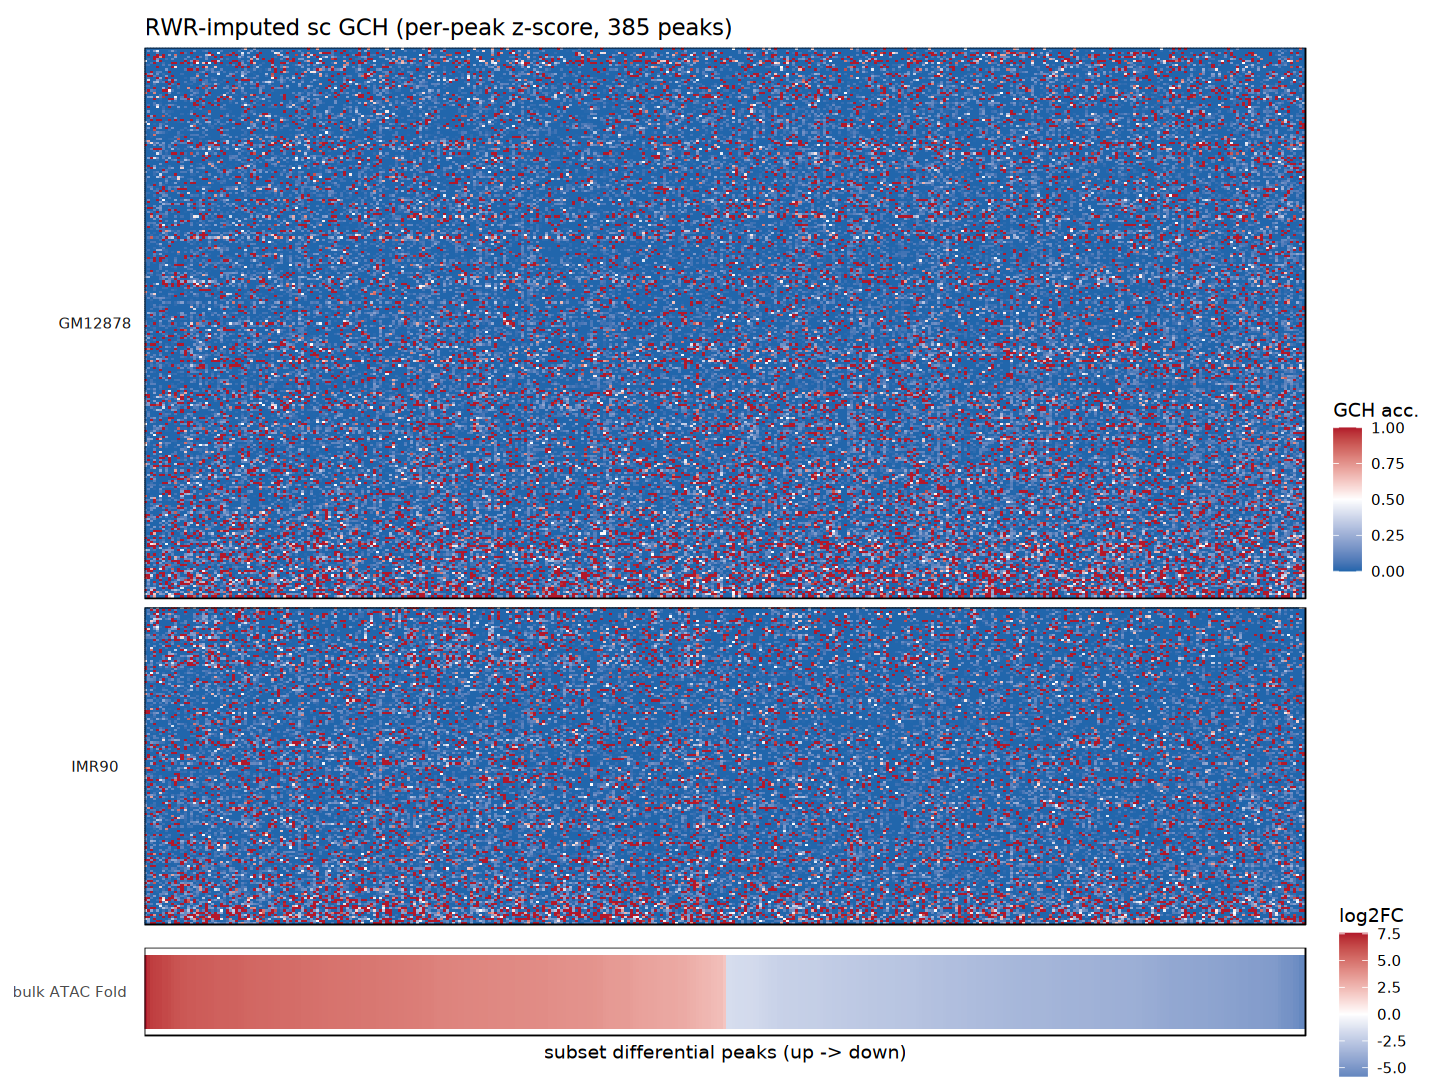

In [31]:
pk_k <- pk[pk$peak_id %in% pid_keep, ]; pk_k <- pk_k[order(-pk_k$Fold), ]   # up -> down
Ai   <- zscore_cols(X_imp[lab, pk_k$peak_id, drop=FALSE])   # per-peak z-score (defined in 5b)
cti  <- ctL
ordi <- order(factor(cti, levels=c("GM12878","IMR90")), rowMeans(Ai))
co   <- lab[ordi]

sc_long <- data.frame(
  cell = factor(rep(co, times=ncol(Ai)), levels=rev(co)),
  peak = factor(rep(pk_k$peak_id, each=length(co)), levels=pk_k$peak_id),
  beta = as.numeric(Ai[co, pk_k$peak_id]),
  cell_type = factor(rep(cti[co], times=ncol(Ai)), levels=c("GM12878","IMR90")))
bulk_long <- data.frame(ref=factor("bulk ATAC Fold"),
  peak=factor(pk_k$peak_id, levels=pk_k$peak_id), fold=pk_k$Fold)

p_sc <- ggplot(sc_long, aes(peak, cell, fill=beta)) + geom_tile() + fill_acc +
  facet_grid(cell_type ~ ., scales="free_y", space="free_y", switch="y") +
  labs(title=sprintf("RWR-imputed sc GCH (per-peak z-score, %d peaks)", nrow(pk_k)), x=NULL, y=NULL) +
  tile_theme + theme(strip.text.y.left=element_text(angle=0, face="bold"), strip.placement="outside")
p_bk <- ggplot(bulk_long, aes(peak, ref, fill=fold)) + geom_tile() +
  scale_fill_gradient2(low="#2166AC", mid="white", high="#B2182B", midpoint=0, name="log2FC") +
  labs(x="subset differential peaks (up -> down)", y=NULL) +
  tile_theme + theme(axis.text.y=element_text(face="bold"))
comb <- (p_sc / p_bk) + plot_layout(heights=c(10, 1.0))
ggsave(file.path(OUTFIG, "fig2_atac_sc_gch_imputed_heatmap.pdf"), comb, width=12, height=9)
options(repr.plot.width=12, repr.plot.height=9); comb


### 6b. Concordance after imputation — sc GCH (GM−IMR) vs bulk ATAC Fold

Pearson r after RWR imputation (bulk Fold vs sc GCH IMR-GM): 0.676


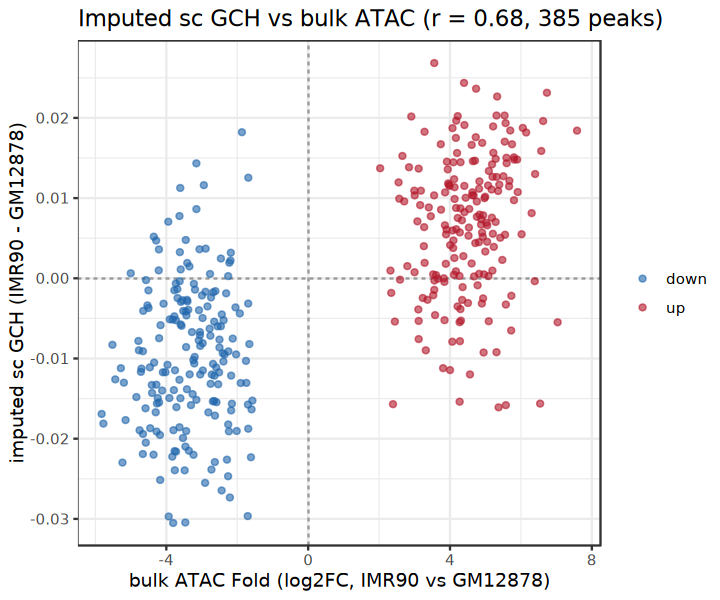

In [32]:
# IMR90 - GM12878 to match bulk Fold direction (Fold>0 = more open in IMR90) -> expect r>0
gm  <- colMeans(X_imp[lab[ctL=="GM12878"], pk_k$peak_id, drop=FALSE])
imr <- colMeans(X_imp[lab[ctL=="IMR90"],   pk_k$peak_id, drop=FALSE])
cc  <- data.frame(peak=pk_k$peak_id, fold=pk_k$Fold, dir=pk_k$dir, sc_diff=imr-gm)
ri <- cor(cc$fold, cc$sc_diff)
cat(sprintf("Pearson r after RWR imputation (bulk Fold vs sc GCH IMR-GM): %.3f\n", ri))

p_con <- ggplot(cc, aes(fold, sc_diff, colour=dir)) +
  geom_hline(yintercept=0, linetype=2, colour="grey60") +
  geom_vline(xintercept=0, linetype=2, colour="grey60") +
  geom_point(alpha=.6, size=1.3) +
  scale_colour_manual(values=c(up="#B2182B", down="#2166AC"), name=NULL) +
  labs(title=sprintf("Imputed sc GCH vs bulk ATAC (r = %.2f, %d peaks)", ri, nrow(pk_k)),
       x="bulk ATAC Fold (log2FC, IMR90 vs GM12878)", y="imputed sc GCH (IMR90 - GM12878)") + theme_bw()
ggsave(file.path(OUTFIG, "fig2_atac_sc_gch_imputed_concordance.pdf"), p_con, width=6, height=5)
options(repr.plot.width=6, repr.plot.height=5); p_con


### 6c. Cell-type pseudobulk (aggregate all cells of each type)

Aggregate **all** cells of each type into one pseudobulk profile (mean of the imputed matrix) and
order peaks IMR90-open → GM12878-open. Colour by **per-peak mean-centered** accessibility
(subtract each peak's mean across the two types) — this keeps the true magnitude of the GM/IMR
difference. (Per-peak *z-score* would divide by the SD and, with only two rows, collapse every peak
to ±0.707 — i.e. a misleading binary; centering avoids that.) The two rows are complementary and
track the bulk ATAC Fold reference below.

cell-type pseudobulk concordance r (IMR-GM vs bulk Fold): 0.676


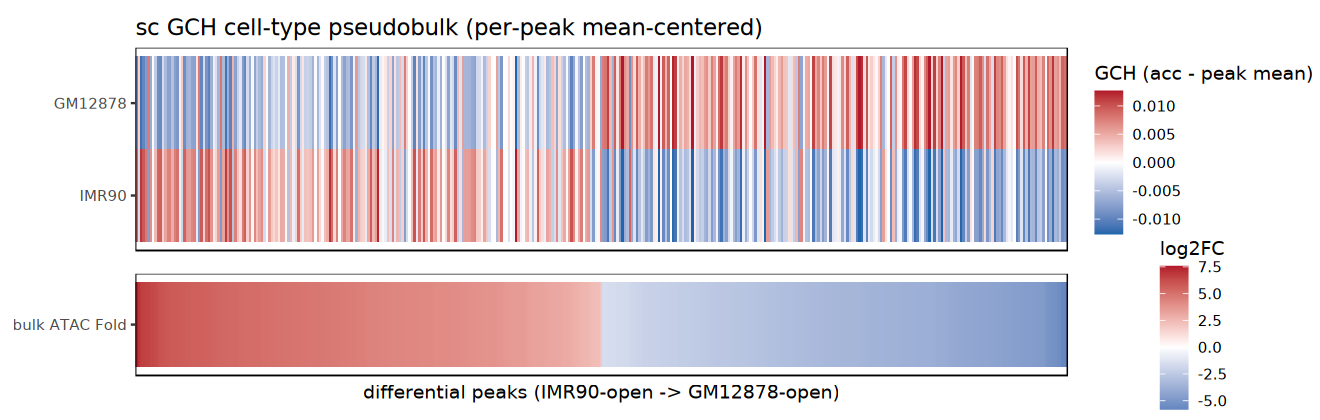

In [36]:
peaks_ord <- pid_keep[order(-pk$Fold[match(pid_keep, pk$peak_id)])]   # IMR-open -> GM-open
PB  <- rbind(GM12878 = colMeans(X_imp[lab[ctL=="GM12878"], pid_keep, drop=FALSE]),
             IMR90   = colMeans(X_imp[lab[ctL=="IMR90"],   pid_keep, drop=FALSE]))
PBc <- sweep(PB, 2, colMeans(PB))                  # per-peak mean-centered (keeps magnitude)
lim <- as.numeric(quantile(abs(PBc), 0.98))        # symmetric colour limit from the data
foldv <- pk$Fold[match(peaks_ord, pk$peak_id)]
cat(sprintf("cell-type pseudobulk concordance r (IMR-GM vs bulk Fold): %.3f\n",
            cor(PB["IMR90",] - PB["GM12878",], pk$Fold[match(pid_keep, pk$peak_id)])))

pb_long <- data.frame(
  type = factor(rep(rownames(PBc), times=length(peaks_ord)), levels=c("IMR90","GM12878")),
  peak = factor(rep(peaks_ord, each=2), levels=peaks_ord),
  v    = as.numeric(PBc[, peaks_ord]))
bulk_long <- data.frame(ref=factor("bulk ATAC Fold"),
  peak=factor(peaks_ord, levels=peaks_ord), fold=foldv)
pb_theme <- theme(axis.text.x=element_blank(), axis.ticks.x=element_blank(), panel.grid=element_blank(),
  panel.background=element_blank(), panel.border=element_rect(colour="black", fill=NA, linewidth=.4),
  axis.text.y=element_text(face="bold"))

p_pb <- ggplot(pb_long, aes(peak, type, fill=v)) + geom_tile() +
  scale_fill_gradient2(low="#2166AC", mid="white", high="#B2182B", midpoint=0, limits=c(-lim, lim),
                       oob=scales::squish, name="GCH (acc - peak mean)") +
  labs(title="sc GCH cell-type pseudobulk (per-peak mean-centered)", x=NULL, y=NULL) + pb_theme
p_bk <- ggplot(bulk_long, aes(peak, ref, fill=fold)) + geom_tile() +
  scale_fill_gradient2(low="#2166AC", mid="white", high="#B2182B", midpoint=0, name="log2FC") +
  labs(x="differential peaks (IMR90-open -> GM12878-open)", y=NULL) + pb_theme
comb <- (p_pb / p_bk) + plot_layout(heights=c(2, 1))
ggsave(file.path(OUTFIG, "fig2_atac_sc_gch_pseudobulk_heatmap.pdf"), comb, width=11, height=3.5)
options(repr.plot.width=11, repr.plot.height=3.5); comb


## 7. 250 kb GCH pseudobulk vs bulk ATAC (read-weighted)

Genome-wide check at 250 kb (parallel to the HCG-vs-WGBS pseudobulk). **Read-weighted** sc GpC
pseudobulk — Σ(methylated GCH reads)/Σ(total reads) pooled across **all** cells of each type
(`codes/build_sc_pseudobulk_gch_250kb.py`, labels from `cell_type_table.tsv`: 281 GM + 160 IMR) —
versus bulk ATAC signal binned to 250 kb (`codes/bin_bulk_atac_250kb.py`).

Bulk ATAC is ENCODE signal p-value (continuous), so concordance is by correlation. Absolute
accessibility tracks bulk well per line; the cell-line *differential* is weak at 250 kb (it is a
peak-scale effect — see the peak-level Part 6 for the differential).

In [ ]:
GCHACC   <- file.path(FIG2, "analysis/gch_acc_250kb")
G_OUTFIG <- file.path(GCHACC, "figures"); dir.create(G_OUTFIG, showWarnings=FALSE, recursive=TRUE)
pbk <- as.data.frame(fread(file.path(GCHACC, "sc_pseudobulk_GCH_250kb.tsv.gz")))
atk <- as.data.frame(fread(file.path(GCHACC, "bulk_atac_250kb.tsv")))
m <- merge(pbk, atk, by="bin_id", suffixes=c("",".bk"))
MINREADS <- 20                                   # require >=20 GCH reads per type per bin
m <- m[m$GM12878_total>=MINREADS & m$IMR90_total>=MINREADS &
       is.finite(m$GM12878_atac) & is.finite(m$IMR90_atac), ]
sp <- function(a,b) cor(a,b,method="spearman", use="complete.obs")
sc_d <- m$IMR90_beta - m$GM12878_beta; bk_d <- log2((m$IMR90_atac+1)/(m$GM12878_atac+1))
cat(sprintf("bins used: %d | GM rho=%.3f | IMR rho=%.3f | differential rho=%.3f\n",
            nrow(m), sp(m$GM12878_beta,m$GM12878_atac), sp(m$IMR90_beta,m$IMR90_atac), sp(sc_d,bk_d)))

p1 <- ggplot(m, aes(log1p(GM12878_atac), GM12878_beta)) +
  geom_point(alpha=.2, size=.4, colour="#2166AC") + geom_smooth(method="lm", se=FALSE, colour="black", linewidth=.4) +
  labs(title=sprintf("GM12878 (rho=%.2f)", sp(m$GM12878_beta,m$GM12878_atac)),
       x="bulk ATAC log1p(signal)", y="sc GCH pseudobulk acc") + theme_bw()
p2 <- ggplot(m, aes(log1p(IMR90_atac), IMR90_beta)) +
  geom_point(alpha=.2, size=.4, colour="#B2182B") + geom_smooth(method="lm", se=FALSE, colour="black", linewidth=.4) +
  labs(title=sprintf("IMR90 (rho=%.2f)", sp(m$IMR90_beta,m$IMR90_atac)),
       x="bulk ATAC log1p(signal)", y="sc GCH pseudobulk acc") + theme_bw()
p3 <- ggplot(data.frame(sc_d, bk_d), aes(bk_d, sc_d)) +
  geom_point(alpha=.2, size=.4, colour="grey30") + geom_hline(yintercept=0, linetype=2) + geom_vline(xintercept=0, linetype=2) +
  geom_smooth(method="lm", se=FALSE, colour="black", linewidth=.4) +
  labs(title=sprintf("Differential (rho=%.2f)", sp(sc_d,bk_d)),
       x="bulk ATAC log2(IMR/GM)", y="sc GCH (IMR-GM)") + theme_bw()
comb <- p1 | p2 | p3
ggsave(file.path(G_OUTFIG, "fig2_gch250kb_pseudobulk_vs_bulk_atac.pdf"), comb, width=13, height=4)
options(repr.plot.width=13, repr.plot.height=4); comb


### 7b. 250 kb pseudobulk heatmap (read-weighted, 6c-style)

Same 2-row pseudobulk heatmap as Part 6c, but using the **correctly-calculated read-weighted
250 kb pseudobulk** (Σmeth/Σtotal pooled per cell type) instead of the mean of per-cell imputed
values. Shown over the top-1000 differential 250 kb bins, per-bin mean-centered (magnitude kept).
The two ENCODE ATAC bigWigs differ in depth/scale, so each bulk track is z-scored (on log1p
signal) before differencing — otherwise the differential is globally biased.

bins shown: 1000 | differential rho=0.767


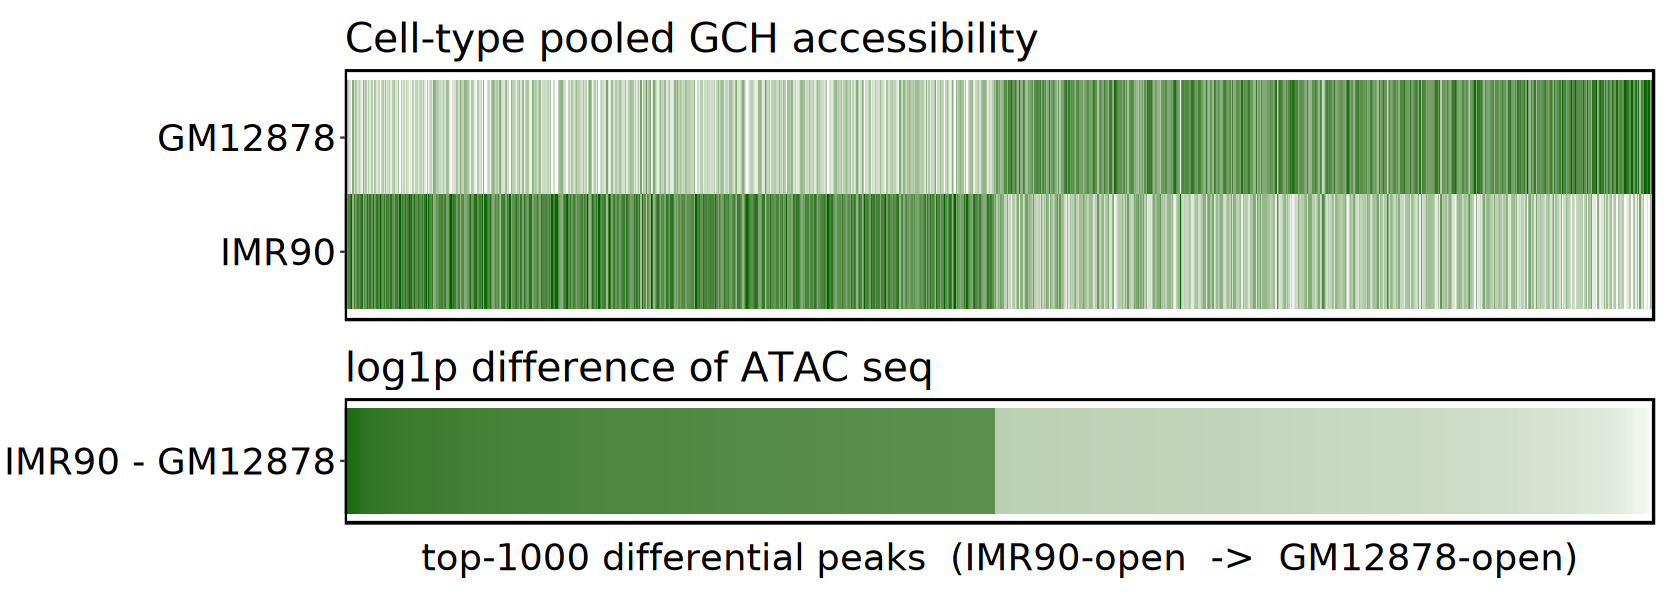

In [49]:
GCHACC   <- file.path(FIG2, "analysis/gch_acc_250kb")
G_OUTFIG <- file.path(GCHACC, "figures"); dir.create(G_OUTFIG, showWarnings=FALSE, recursive=TRUE)
pbk <- as.data.frame(fread(file.path(GCHACC, "sc_pseudobulk_GCH_250kb.tsv.gz")))
atk <- as.data.frame(fread(file.path(GCHACC, "bulk_atac_250kb.tsv")))
h <- merge(pbk, atk, by="bin_id", suffixes=c("",".bk"))
MINREADS <- 20; N_TOP <- 1000
h <- h[h$GM12878_total>=MINREADS & h$IMR90_total>=MINREADS &
       is.finite(h$GM12878_atac) & is.finite(h$IMR90_atac), ]
# per-track z-score (log1p) before differencing (the two ATAC bigWigs differ in depth); >0 = IMR-open
h$bulk_d <- scale(log1p(h$IMR90_atac))[,1] - scale(log1p(h$GM12878_atac))[,1]
h <- h[order(-abs(h$bulk_d)), ][seq_len(min(N_TOP, nrow(h))), ]
h <- h[order(-h$bulk_d), ]; bins_ord <- h$bin_id                       # IMR90-open -> GM12878-open

PB  <- rbind(GM12878=h$GM12878_beta, IMR90=h$IMR90_beta); colnames(PB) <- bins_ord
PBc <- sweep(PB, 2, colMeans(PB)); lim <- as.numeric(quantile(abs(PBc), 0.98))   # per-bin mean-centered
cat(sprintf("bins shown: %d | differential rho=%.3f\n", length(bins_ord),
            cor(h$IMR90_beta-h$GM12878_beta, h$bulk_d, method="spearman")))

# publication theme: larger text (matches methylation notebook pub_tile)
pub_tile <- theme(
  axis.text.x  = element_blank(), axis.ticks.x = element_blank(),
  axis.text.y  = element_text(size = 22, face = "bold", colour = "black"),
  axis.title.x = element_text(size = 22, margin = margin(t = 9)),
  panel.grid = element_blank(), panel.background = element_blank(),
  panel.border = element_rect(colour = "black", fill = NA, linewidth = 1.1),
  plot.title = element_text(size = 24, face = "bold"), strip.background = element_blank(),
  legend.position = "none",
  plot.margin = margin(8, 10, 8, 10))

hm_long <- data.frame(type=factor(rep(rownames(PBc), times=ncol(PBc)), levels=c("IMR90","GM12878")),
  bin=factor(rep(bins_ord, each=2), levels=bins_ord), v=as.numeric(PBc[, bins_ord]))
bulk_long <- data.frame(ref=factor("IMR90 - GM12878"),
  bin=factor(bins_ord, levels=bins_ord), fold=h$bulk_d)
p_pb <- ggplot(hm_long, aes(bin, type, fill=v)) + geom_tile() +
  scale_fill_gradient(low="white", high="darkgreen", limits=c(-lim, lim),
                      oob=scales::squish, name="GpC acc.\n(centered)") +
  labs(title="Cell-type pooled GCH accessibility", x=NULL, y=NULL) + pub_tile
p_bk <- ggplot(bulk_long, aes(bin, ref, fill=fold)) + geom_tile() +
  scale_fill_gradient(low="white", high="darkgreen", limits=max(abs(h$bulk_d))*c(-1,1),
                      oob=scales::squish, name="ATAC\nz-diff") +
  labs(title="log1p difference of ATAC seq",
       x=sprintf("top-%d differential peaks  (IMR90-open  ->  GM12878-open)", length(bins_ord)), y=NULL) + pub_tile
comb <- (p_pb / p_bk) + plot_layout(heights=c(2, 1))
ggsave(file.path(G_OUTFIG, "fig2_gch250kb_pseudobulk_heatmap.pdf"), comb, width=14, height=5.0)
options(repr.plot.width=14, repr.plot.height=5.0); comb


### 7c. Two-row bulk variant (GM12878 & IMR90 shown separately)

Same as 7b, but the bulk ATAC ground truth is shown as **two rows** — per-track z(log1p signal)
for GM12878 and IMR90 — instead of a single difference row. Both panels use white -> darkgreen
(white = low, darkgreen = high). Each bulk track is z-scored per cell line, which removes the
depth/scale difference between the two ENCODE bigWigs so the two rows are comparable.

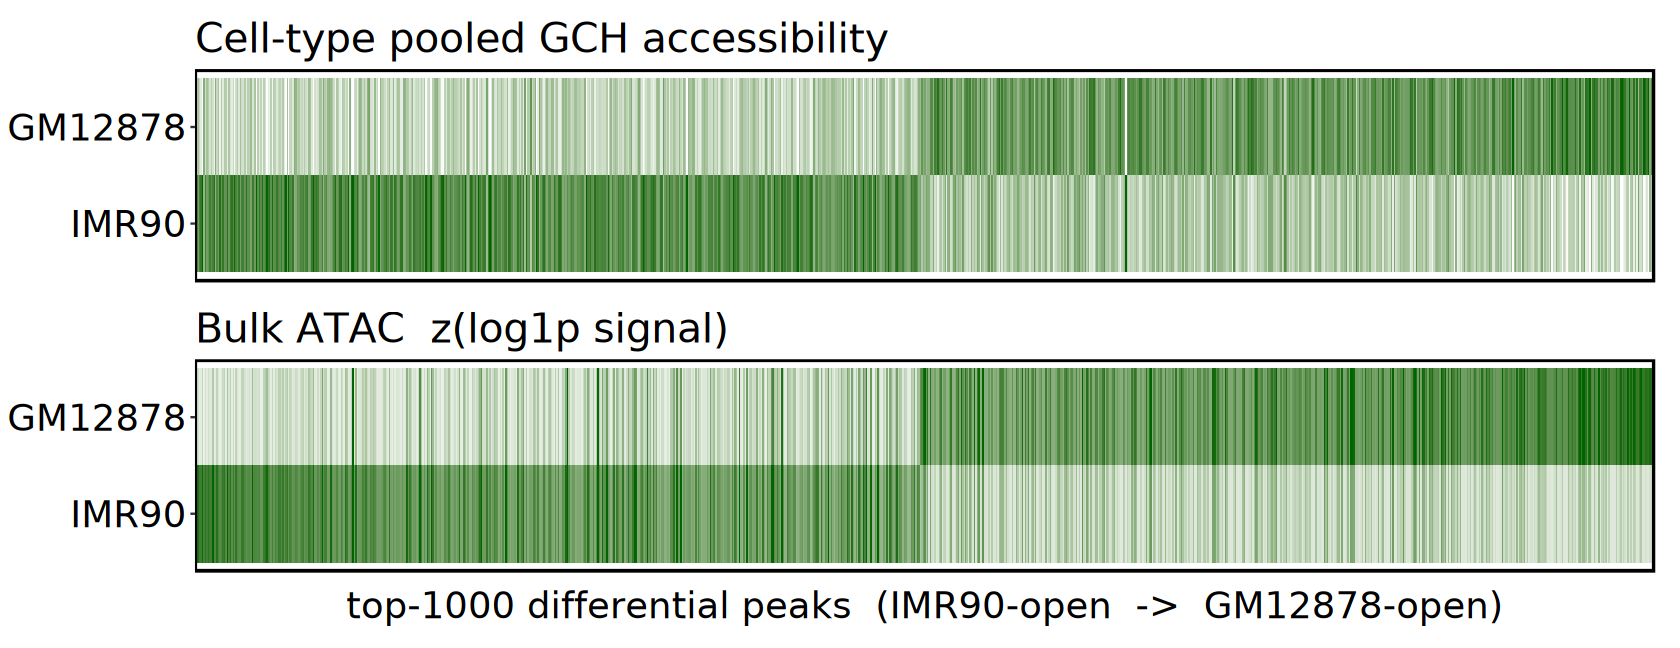

In [50]:
GCHACC   <- file.path(FIG2, "analysis/gch_acc_250kb")
G_OUTFIG <- file.path(GCHACC, "figures"); dir.create(G_OUTFIG, showWarnings=FALSE, recursive=TRUE)
pbk <- as.data.frame(fread(file.path(GCHACC, "sc_pseudobulk_GCH_250kb.tsv.gz")))
atk <- as.data.frame(fread(file.path(GCHACC, "bulk_atac_250kb.tsv")))
h <- merge(pbk, atk, by="bin_id", suffixes=c("",".bk"))
MINREADS <- 20; N_TOP <- 1000
h <- h[h$GM12878_total>=MINREADS & h$IMR90_total>=MINREADS &
       is.finite(h$GM12878_atac) & is.finite(h$IMR90_atac), ]
h$zG <- scale(log1p(h$GM12878_atac))[,1]; h$zI <- scale(log1p(h$IMR90_atac))[,1]; h$bulk_d <- h$zI - h$zG
h <- h[order(-abs(h$bulk_d)), ][seq_len(min(N_TOP, nrow(h))), ]
h <- h[order(-h$bulk_d), ]; bins_ord <- h$bin_id

PB  <- rbind(GM12878=h$GM12878_beta, IMR90=h$IMR90_beta); colnames(PB) <- bins_ord
PBc <- sweep(PB, 2, colMeans(PB)); lim <- as.numeric(quantile(abs(PBc), 0.98))
zl  <- max(abs(as.numeric(quantile(c(h$zG, h$zI), c(0.02, 0.98)))))

pub_tile <- theme(
  axis.text.x  = element_blank(), axis.ticks.x = element_blank(),
  axis.text.y  = element_text(size = 22, face = "bold", colour = "black"),
  axis.title.x = element_text(size = 22, margin = margin(t = 9)),
  panel.grid = element_blank(), panel.background = element_blank(),
  panel.border = element_rect(colour = "black", fill = NA, linewidth = 1.1),
  plot.title = element_text(size = 24, face = "bold"), strip.background = element_blank(),
  legend.position = "none", plot.margin = margin(8, 10, 8, 10))

sc_long <- data.frame(type=factor(rep(rownames(PBc), times=ncol(PBc)), levels=c("IMR90","GM12878")),
  bin=factor(rep(bins_ord, each=2), levels=bins_ord), v=as.numeric(PBc[, bins_ord]))
bulk2 <- data.frame(type=factor(rep(c("GM12878","IMR90"), each=length(bins_ord)), levels=c("IMR90","GM12878")),
  bin=factor(rep(bins_ord, times=2), levels=bins_ord), v=c(h$zG, h$zI))
p_sc <- ggplot(sc_long, aes(bin, type, fill=v)) + geom_tile() +
  scale_fill_gradient(low="white", high="darkgreen", limits=c(-lim, lim), oob=scales::squish, name="GpC") +
  labs(title="Cell-type pooled GCH accessibility", x=NULL, y=NULL) + pub_tile
p_b2 <- ggplot(bulk2, aes(bin, type, fill=v)) + geom_tile() +
  scale_fill_gradient(low="white", high="darkgreen", limits=c(-zl, zl), oob=scales::squish, name="ATAC z(log1p)") +
  labs(title="Bulk ATAC  z(log1p signal)",
       x=sprintf("top-%d differential peaks  (IMR90-open  ->  GM12878-open)", length(bins_ord)), y=NULL) + pub_tile
comb <- (p_sc / p_b2) + plot_layout(heights=c(1, 1))
ggsave(file.path(G_OUTFIG, "fig2_gch250kb_pseudobulk_2row_heatmap.pdf"), comb, width=14, height=5.4)
options(repr.plot.width=14, repr.plot.height=5.4); comb


### 7d. Colorbars for the 7c heatmap

The 7c panels have their legends switched off for a clean publication figure, so the colour
scales are rendered here as **standalone horizontal colorbars** — same white -> darkgreen ramp
and the identical limits used in 7c: one for the single-cell **GCH accessibility** (per-bin
mean-centered, +-`lim`) and one for the **bulk ATAC z(log1p signal)** (+-`zl`).

Run Part 7c first (this cell reuses its `lim`, `zl`, `G_OUTFIG`).

In [1]:
stopifnot(exists("lim"), exists("zl"), exists("G_OUTFIG"))   # from Part 7c

cbar <- function(lo, hi, title, fmt="%.3f", n=256) {
  d <- data.frame(x = seq(lo, hi, length.out = n), y = 1)
  ggplot(d, aes(x, y, fill = x)) + geom_raster() +
    scale_fill_gradient(low = "white", high = "darkgreen", limits = c(lo, hi), guide = "none") +
    scale_x_continuous(breaks = c(lo, 0, hi), labels = function(b) sprintf(fmt, b), expand = c(0,0)) +
    scale_y_continuous(expand = c(0,0)) +
    labs(title = title, x = NULL, y = NULL) +
    theme(axis.text.x = element_text(size = 16, colour = "black"),
          axis.ticks.x = element_line(colour = "black"),
          axis.text.y = element_blank(), axis.ticks.y = element_blank(),
          panel.background = element_blank(), panel.grid = element_blank(),
          panel.border = element_rect(colour = "black", fill = NA, linewidth = 1.1),
          plot.title = element_text(size = 18, face = "bold"),
          plot.margin = margin(4, 26, 4, 26))
}
cb1 <- cbar(-lim, lim, "GCH accessibility (centered)")
cb2 <- cbar(-zl,  zl,  "Bulk ATAC  z(log1p signal)", fmt = "%.1f")
cbs <- cb1 / cb2
ggsave(file.path(G_OUTFIG, "fig2_gch250kb_2row_colorbars.pdf"), cbs, width = 6.6, height = 2.4)
options(repr.plot.width = 6.6, repr.plot.height = 2.4); cbs


ERROR: Error: exists("lim") is not TRUE
